#Data preprocessing

In [ ]:
import pandas as pd, numpy as np, os
import kagglehub
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    print("Loading file:", csv_path)
    df = pd.read_csv(csv_path)
else:
    df = pd.read_csv(path)

df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Loading file: /kaggle/input/creditcardfraud/creditcard.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.shape



(284807, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
print(df.isnull().sum())


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 1081


In [ ]:
print(df["Class"].value_counts())


Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
df[df.isnull().any(axis=1)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [ ]:
# summary statistics
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.0,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


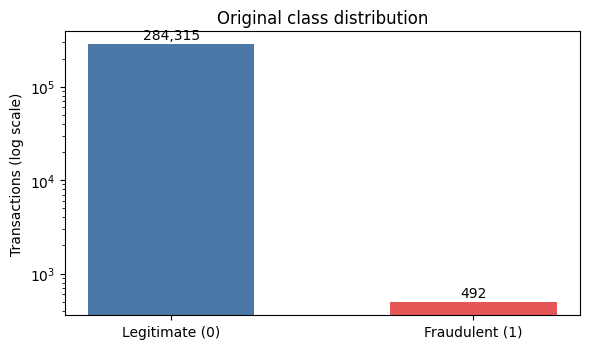

In [ ]:
# class distribution


print(df['Class'].value_counts())
print("Fraud rate: {:.4%}".format(df['Class'].mean()))

fraud = df['Class'].value_counts()
fig, ax = plt.subplots(figsize=(6,3.6))
bars = ax.bar(['Legitimate (0)','Fraudulent (1)'], [fraud[0], fraud[1]],
              color=['#4C78A8','#E45756'], width=0.55)
ax.set_yscale('log'); ax.set_ylabel('Transactions (log scale)')
for b, v in zip(bars, [fraud[0], fraud[1]]):
    ax.text(b.get_x()+b.get_width()/2, v*1.15, f'{v:,}', ha='center')
ax.set_title('Original class distribution')
plt.tight_layout()
plt.savefig('figure_1_original_class_distribution.png', dpi=200)
plt.show()


In [ ]:
# duplicates and anomalies


print("Duplicate rows:", df.duplicated().sum())
print("Negative amounts:", (df['Amount'] < 0).sum())



Duplicate rows: 1081
Negative amounts: 0


In [ ]:
# remove duplicate rows
before_count = len(df)
df = df.drop_duplicates().reset_index(drop=True)
after_count = len(df)
print(f"Removed {before_count - after_count} duplicate rows.")
print(f"New dataset shape: {df.shape}")

Removed 1081 duplicate rows.
New dataset shape: (283726, 31)


In [ ]:
# correlation with label


corr = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)
print(corr.head(10).round(3))


V17    0.313
V14    0.293
V12    0.251
V10    0.207
V16    0.187
V3     0.182
V7     0.172
V11    0.149
V4     0.129
V18    0.105
Name: Class, dtype: float64


Class
0    198242
1       366
Name: count, dtype: int64 Class
0    28339
1       33
Name: count, dtype: int64 Class
0    56672
1       74
Name: count, dtype: int64


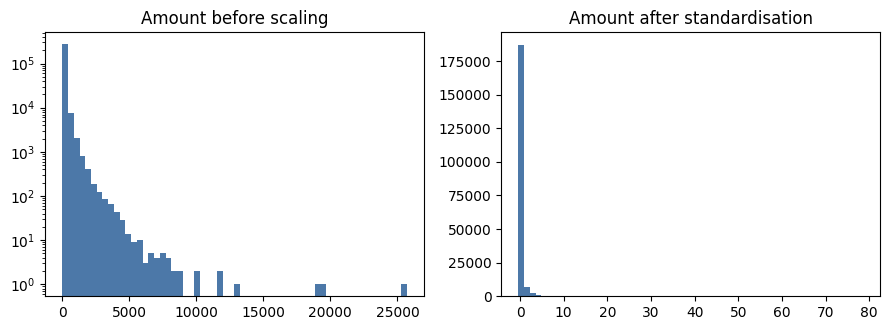

In [ ]:
# time-aware split, standardise Amount
df_sorted = df.sort_values('Time').reset_index(drop=True)
cut_tr = int(len(df_sorted) * 0.70)
cut_val = int(len(df_sorted) * 0.80)

train_df = df_sorted[:cut_tr]
val_df   = df_sorted[cut_tr:cut_val]
test_df  = df_sorted[cut_val:]

y_tr, y_val, y_te = train_df['Class'], val_df['Class'], test_df['Class']

scaler = StandardScaler()
X_tr  = train_df.copy()
X_val = val_df.copy()
X_te  = test_df.copy()
X_tr['Amount_s']  = scaler.fit_transform(X_tr[['Amount']])
X_val['Amount_s'] = scaler.transform(X_val[['Amount']])
X_te['Amount_s']  = scaler.transform(X_te[['Amount']])

print(y_tr.value_counts(), y_val.value_counts(), y_te.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(df['Amount'], bins=60, color='#4C78A8')
axes[0].set_title('Amount before scaling'); axes[0].set_yscale('log')
axes[1].hist(X_tr['Amount_s'], bins=60, color='#4C78A8')
axes[1].set_title('Amount after standardisation')
plt.tight_layout()
plt.savefig('figure_2_amount_before_after_scaling.png', dpi=200)
plt.show()

df[['Amount']].describe().T.round(3).to_csv('table_3_transformation_log.csv')



In [ ]:
# split class distributions


splits = pd.DataFrame({
    'Total':   [len(y_tr), len(y_val), len(y_te)],
    'Legit':   [(y_tr==0).sum(), (y_val==0).sum(), (y_te==0).sum()],
    'Fraud':   [(y_tr==1).sum(), (y_val==1).sum(), (y_te==1).sum()],
}, index=['Train (70%)','Validation (10%)','Test (20%)'])
print(splits)
splits.to_csv('table_2_split_class_distributions.csv')


                   Total   Legit  Fraud
Train (70%)       198608  198242    366
Validation (10%)   28372   28339     33
Test (20%)         56746   56672     74


                  Legitimate  Fraudulent  Fraud rate %
None                  198242         366      0.184283
SMOTE                 198242      198242     50.000000
Borderline-SMOTE      198242      198242     50.000000
ADASYN                198242      198116     49.984105
Undersample              366         366     50.000000


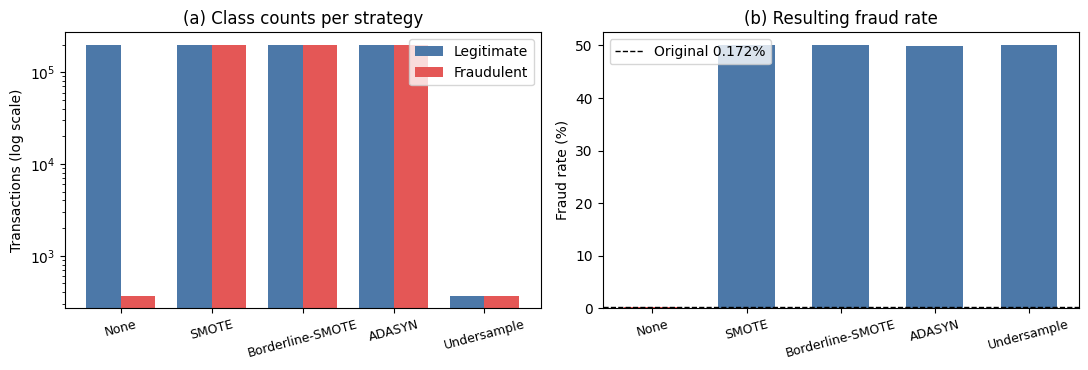

In [ ]:
# resampling strategies on train only
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

stats = {}
def dist(name, yv):
    stats[name] = [(yv==0).sum(), (yv==1).sum()]
dist('None', y_tr)

_, y_smote  = SMOTE(random_state=42).fit_resample(X_tr[['Amount_s']], y_tr)
dist('SMOTE', pd.Series(y_smote))
_, y_bsmote = BorderlineSMOTE(random_state=42).fit_resample(X_tr[['Amount_s']], y_tr)
dist('Borderline-SMOTE', pd.Series(y_bsmote))
_, y_adasyn = ADASYN(random_state=42).fit_resample(X_tr[['Amount_s']], y_tr)
dist('ADASYN', pd.Series(y_adasyn))
_, y_rus    = RandomUnderSampler(random_state=42).fit_resample(X_tr[['Amount_s']], y_tr)
dist('Undersample', pd.Series(y_rus))

res = pd.DataFrame(stats, index=['Legitimate','Fraudulent']).T
res['Fraud rate %'] = res['Fraudulent'] / (res['Legitimate'] + res['Fraudulent']) * 100
print(res)
res.to_csv('table_4_training_distributions.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(res)); w = 0.38

ax1.bar(x - w/2, res['Legitimate'], w, label='Legitimate', color='#4C78A8')
ax1.bar(x + w/2, res['Fraudulent'], w, label='Fraudulent', color='#E45756')
ax1.set_yscale('log'); ax1.set_ylabel('Transactions (log scale)')
ax1.set_xticks(x); ax1.set_xticklabels(res.index, fontsize=9, rotation=15)
ax1.legend(); ax1.set_title('(a) Class counts per strategy')

colors = ['#4C78A8' if r > 1 else '#E45756' for r in res['Fraud rate %']]
ax2.bar(x, res['Fraud rate %'], 0.6, color=colors)
ax2.axhline(0.172, color='k', linestyle='--', linewidth=1, label='Original 0.172%')
ax2.set_ylabel('Fraud rate (%)')
ax2.set_xticks(x); ax2.set_xticklabels(res.index, fontsize=9, rotation=15)
ax2.legend(); ax2.set_title('(b) Resulting fraud rate')

plt.tight_layout()
plt.savefig('figure_3_training_resampling.png', dpi=200)
plt.show()

#Cell A – Imports

In [ ]:
!pip install -q xgboost imbalanced-learn optuna shap

import os, sys, time, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb, optuna, shap
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import EditedNearestNeighbours, RandomUnderSampler

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEED = 42
np.random.seed(SEED)

#Cell B – Build the feature set (paper Section 3.2)

In [ ]:
for d in (X_tr, X_val, X_te):
    d['Hour'] = (d['Time'] // 3600) % 24

hour_scaler = StandardScaler().fit(X_tr[['Hour']])
for d in (X_tr, X_val, X_te):
    d['Hour_s'] = hour_scaler.transform(d[['Hour']]).ravel()

FEATURES = [f'V{i}' for i in range(1, 29)] + ['Amount_s', 'Hour_s']
Xtr, Xva, Xte = X_tr[FEATURES], X_val[FEATURES], X_te[FEATURES]
print(Xtr.shape, Xva.shape, Xte.shape)

(198608, 30) (28372, 30) (56746, 30)


#Cell C – SMOTE-ENN on the training set only (paper Section 3.2)

In [ ]:
# SMOTE to create sinthetic frauds up to 1:1, then ENN removes noisy/overlapping samples
t0 = time.time()
smote_enn = SMOTEENN(
    smote=SMOTE(random_state=SEED),
    enn=EditedNearestNeighbours(sampling_strategy='all', n_jobs=-1),
    random_state=SEED)
X_res, y_res = smote_enn.fit_resample(Xtr, y_tr)
print(f"Done in {(time.time()-t0)/60:.1f} min")
print("Before:", np.bincount(y_tr), "| After:", np.bincount(y_res))

joblib.dump((X_res, y_res), 'train_smoteenn.joblib')

Done in 15.9 min
Before: [198242    366] | After: [197906 198242]


['train_smoteenn.joblib']

#Import to drive SMOTE generated samples

In [ ]:
from google.colab import drive
import shutil, os
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/CloudAI_CW1'
os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy('train_smoteenn.joblib', SAVE_DIR)
print(os.listdir(SAVE_DIR))

Mounted at /content/drive
['data', 'train_smoteenn.joblib']


#Cell D – Resampling summary table

In [ ]:
smoteenn_tbl = pd.DataFrame({
    'Legitimate': [(y_tr==0).sum(), (y_res==0).sum()],
    'Fraudulent': [(y_tr==1).sum(), (y_res==1).sum()],
}, index=['Original train', 'After SMOTE-ENN'])
smoteenn_tbl['Fraud rate %'] = smoteenn_tbl['Fraudulent'] / smoteenn_tbl.sum(axis=1) * 100
smoteenn_tbl['Removed by ENN'] = [0, 2*(y_tr==0).sum() - len(y_res)]
print(smoteenn_tbl)
smoteenn_tbl.to_csv('table_5_smoteenn_distribution.csv')

                 Legitimate  Fraudulent  Fraud rate %  Removed by ENN
Original train       198242         366      0.184283               0
After SMOTE-ENN      197906      198242     50.042408             336


#Cell E – Train XGBoost with the paper's hyperparameters (paper Section 3.3)

In [ ]:
params = dict(
    max_depth=6,
    learning_rate=0.01,
    n_estimators=500,
    scale_pos_weight=10,
    eval_metric=['aucpr', 'auc'],
    early_stopping_rounds=50,
    tree_method='hist',
    random_state=SEED,
    n_jobs=-1,
)
model = xgb.XGBClassifier(**params)
t0 = time.time()
model.fit(X_res, y_res,
          eval_set=[(X_res, y_res), (Xva, y_val)],   # validation must be last
          verbose=50)
print(f"Training time: {time.time()-t0:.1f}s | best iteration: {model.best_iteration}")

[0]	validation_0-aucpr:0.96042	validation_0-auc:0.97789	validation_1-aucpr:0.02062	validation_1-auc:0.94848
[50]	validation_0-aucpr:0.99629	validation_0-auc:0.99700	validation_1-aucpr:0.28951	validation_1-auc:0.97030
[90]	validation_0-aucpr:0.99759	validation_0-auc:0.99815	validation_1-aucpr:0.37485	validation_1-auc:0.96394
Training time: 15.6s | best iteration: 40


#Cell F – Learning curves

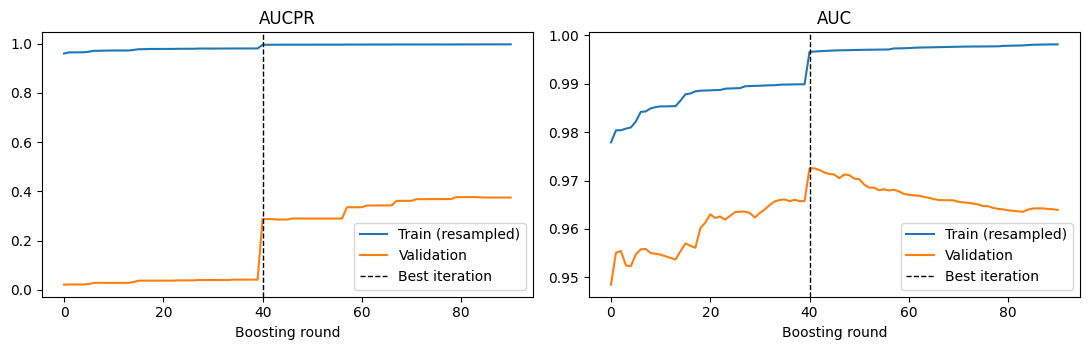

In [ ]:
ev = model.evals_result()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, m in enumerate(['aucpr', 'auc']):
    ax[i].plot(ev['validation_0'][m], label='Train (resampled)')
    ax[i].plot(ev['validation_1'][m], label='Validation')
    ax[i].axvline(model.best_iteration, color='k', ls='--', lw=1, label='Best iteration')
    ax[i].set_title(m.upper()); ax[i].set_xlabel('Boosting round'); ax[i].legend()
plt.tight_layout(); plt.savefig('figure_4_xgb_learning_curves.png', dpi=200); plt.show()

#Cell G – Threshold tuning with Youden's J (paper Section 3.4)


Youden's J threshold: 0.8835  (paper: 0.32)
Threshold with FPR <= 0.1%: 1.0000


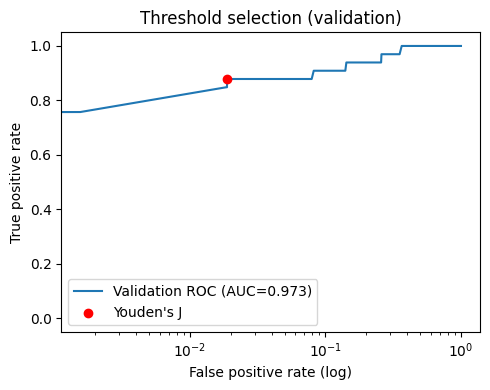

In [ ]:
val_proba = model.predict_proba(Xva)[:, 1]
fpr, tpr, thr = roc_curve(y_val, val_proba)

# youden's j = sensitivity + specificity - 1 = TPR - FPR
j = tpr - fpr
thr_youden = float(min(thr[np.argmax(j)], 1.0))

ok = fpr <= 0.001
thr_cap = float(min(thr[ok][np.argmax(tpr[ok])], 1.0))

print(f"Youden's J threshold: {thr_youden:.4f}  (paper: 0.32)")
print(f"Threshold with FPR <= 0.1%: {thr_cap:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'Validation ROC (AUC={roc_auc_score(y_val, val_proba):.3f})')
plt.scatter(fpr[np.argmax(j)], tpr[np.argmax(j)], c='r', zorder=3, label="Youden's J")
plt.xscale('log'); plt.xlabel('False positive rate (log)'); plt.ylabel('True positive rate')
plt.legend(); plt.title('Threshold selection (validation)')
plt.tight_layout(); plt.savefig('figure_5_threshold_selection.png', dpi=200); plt.show()

#Cell H – Final evaluation on the test set (paper Sections 3.6 and 4.1)

In [ ]:
def evaluate(name, y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return dict(Model=name, Threshold=round(t, 4),
                Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                AUC_ROC=roc_auc_score(y_true, proba),
                PR_AUC=average_precision_score(y_true, proba),
                TP=tp, FP=fp, FN=fn, TN=tn)

test_proba = model.predict_proba(Xte)[:, 1]
results = pd.DataFrame([
    evaluate('XGBoost+SMOTE-ENN @0.5',      y_te, test_proba, 0.5),
    evaluate("XGBoost+SMOTE-ENN @Youden",   y_te, test_proba, thr_youden),
    evaluate('XGBoost+SMOTE-ENN @FPR<=0.1%', y_te, test_proba, thr_cap),
])
display(results.round(4))
results.to_csv('table_6_test_results.csv', index=False)

,Model,Threshold,Precision,Recall,F1,AUC_ROC,PR_AUC,TP,FP,FN,TN
0,XGBoost+SMOTE-ENN @0.5,0.5000,0.0013,1.0000,0.0026,0.9282,0.3475,74,56671,0,1
1,XGBoost+SMOTE-ENN @Youden,0.8835,0.0578,0.8378,0.1081,0.9282,0.3475,62,1011,12,55661
2,XGBoost+SMOTE-ENN @FPR<=0.1%,1.0000,0.0000,0.0000,0.0000,0.9282,0.3475,0,0,74,56672


#Cell I – Confusion matrix, ROC and PR curves (test)

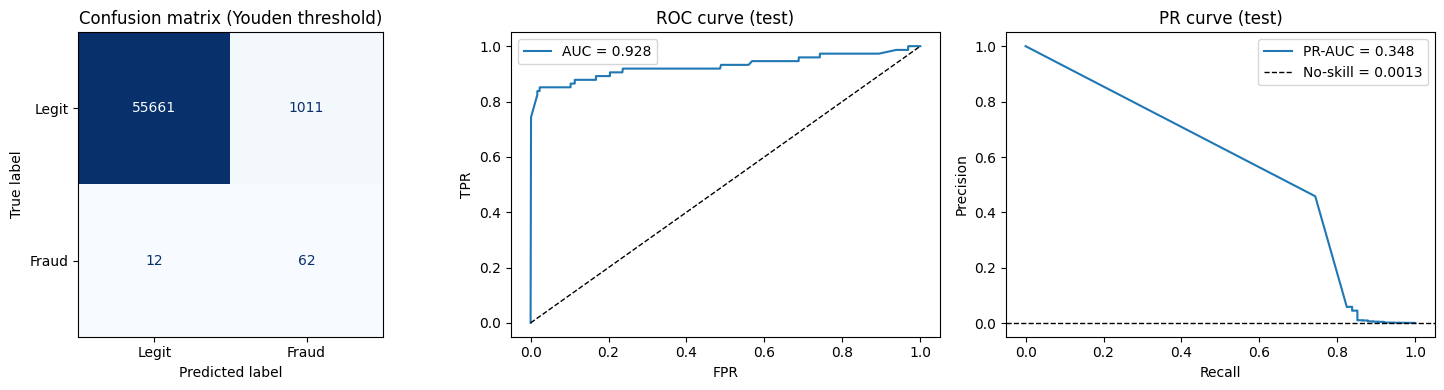

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, (test_proba >= thr_youden).astype(int)),
                       display_labels=['Legit', 'Fraud']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Confusion matrix (Youden threshold)")

f, t, _ = roc_curve(y_te, test_proba)
ax[1].plot(f, t, label=f'AUC = {roc_auc_score(y_te, test_proba):.3f}')
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
ax[1].set_title('ROC curve (test)'); ax[1].legend()

p, r, _ = precision_recall_curve(y_te, test_proba)
ax[2].plot(r, p, label=f'PR-AUC = {average_precision_score(y_te, test_proba):.3f}')
ax[2].axhline(y_te.mean(), color='k', ls='--', lw=1, label=f'No-skill = {y_te.mean():.4f}')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].set_title('PR curve (test)'); ax[2].legend()
plt.tight_layout(); plt.savefig('figure_6_test_evaluation.png', dpi=200); plt.show()

#Cell J – Cost-sensitive analysis (paper Section 3.5)

In [ ]:
FP_COST, FN_COST = 2.40, 280.0
results['Total_cost_$'] = results['FP'] * FP_COST + results['FN'] * FN_COST
display(results[['Model', 'Threshold', 'FP', 'FN', 'Total_cost_$']])

ths = np.linspace(0.01, 0.99, 99)
val_cost = [((val_proba >= t) & (y_val == 0)).sum() * FP_COST +
            ((val_proba <  t) & (y_val == 1)).sum() * FN_COST for t in ths]
thr_cost = ths[int(np.argmin(val_cost))]
print("Cost-optimal threshold (validation):", thr_cost)
display(pd.DataFrame([evaluate('XGBoost+SMOTE-ENN @cost-opt', y_te, test_proba, thr_cost)]).round(4))

,Model,Threshold,FP,FN,Total_cost_$
0,XGBoost+SMOTE-ENN @0.5,0.5000,56671,0,136010.4
1,XGBoost+SMOTE-ENN @Youden,0.8835,1011,12,5786.4
2,XGBoost+SMOTE-ENN @FPR<=0.1%,1.0000,0,74,20720.0


Cost-optimal threshold (validation): 0.88


,Model,Threshold,Precision,Recall,F1,AUC_ROC,PR_AUC,TP,FP,FN,TN
0,XGBoost+SMOTE-ENN @cost-opt,0.88,0.054,0.8378,0.1014,0.9282,0.3475,62,1087,12,55585


#Cell K – Ablation: does SMOTE-ENN actually help?

In [ ]:
# the paper claims SMOTE-ENN improves minority-class recall by 22%, test with the same XGBoost settings
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(Xtr, y_tr)
train_sets = {
    'No resampling': (Xtr, y_tr),
    'SMOTE only':    (X_sm, y_sm),
    'SMOTE-ENN':     (X_res, y_res),
}
abl = []
for name, (Xa, ya) in train_sets.items():
    m = xgb.XGBClassifier(**params)
    m.fit(Xa, ya, eval_set=[(Xva, y_val)], verbose=0)
    vp = m.predict_proba(Xva)[:, 1]
    f, t, th = roc_curve(y_val, vp)
    abl.append(evaluate(name, y_te, m.predict_proba(Xte)[:, 1], float(min(th[np.argmax(t - f)], 1.0))))
ablation = pd.DataFrame(abl)
display(ablation.round(4))
ablation.to_csv('table_7_ablation_resampling.csv', index=False)

,Model,Threshold,Precision,Recall,F1,AUC_ROC,PR_AUC,TP,FP,FN,TN
0,No resampling,0.1035,0.3209,0.8108,0.4598,0.9750,0.7721,60,127,14,56545
1,SMOTE only,0.8821,0.0578,0.8378,0.1082,0.9286,0.3262,62,1010,12,55662
2,SMOTE-ENN,0.8835,0.0578,0.8378,0.1081,0.9282,0.3475,62,1011,12,55661


#Cell L – Inference latency (paper Table 2)

In [ ]:
one = Xte.iloc[[0]]
model.predict_proba(one)
n = 500; t0 = time.perf_counter()
for _ in range(n): model.predict_proba(one)
lat_ms = (time.perf_counter() - t0) / n * 1000

t0 = time.perf_counter(); model.predict_proba(Xte); batch_s = time.perf_counter() - t0
print(f"Single-transaction latency: {lat_ms:.2f} ms  (paper: 12 ms)")
print(f"Batch throughput: {len(Xte)/batch_s:,.0f} transactions/s on Colab CPU")

Single-transaction latency: 3.30 ms  (paper: 12 ms)
Batch throughput: 737,679 transactions/s on Colab CPU


#Cell M – Explainability with SHAP (paper Section 2.4 and Future Work)

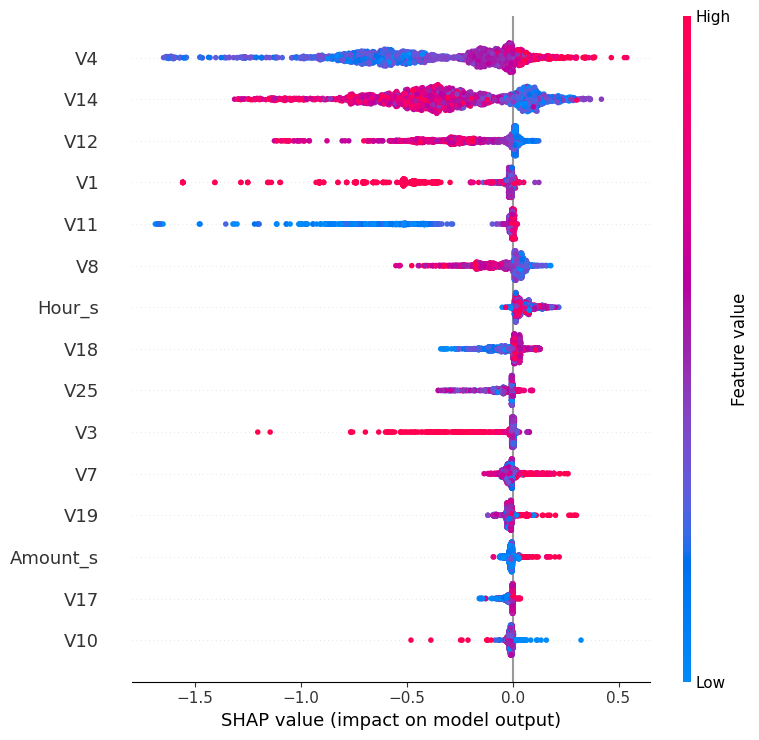

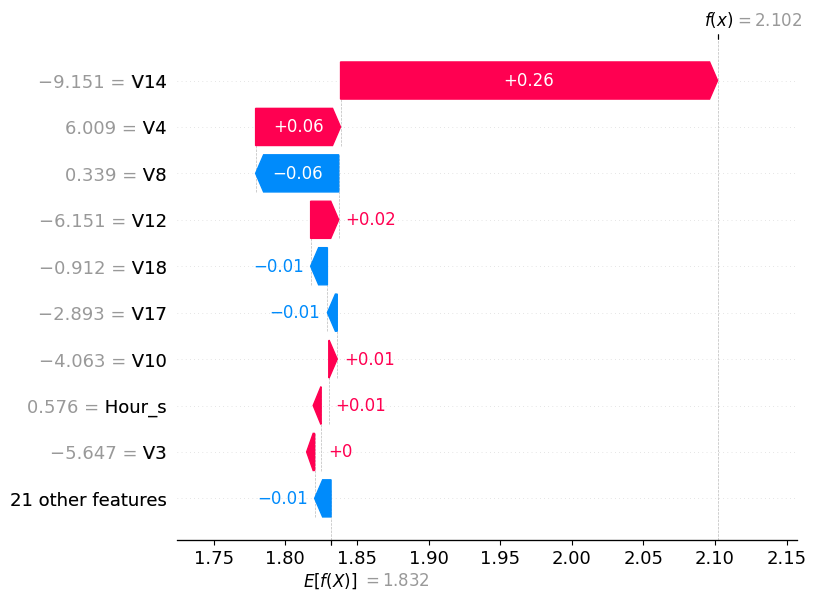

In [ ]:
import shap
explainer = shap.TreeExplainer(model)
sample = Xte.sample(2000, random_state=SEED)
shap.summary_plot(explainer.shap_values(sample), sample, max_display=15, show=False)
plt.tight_layout(); plt.savefig('figure_7_shap_summary.png', dpi=200); plt.show()

pos = np.where((test_proba >= thr_youden) & (y_te.values == 1))[0]
if len(pos):
    shap.plots.waterfall(explainer(Xte.iloc[[pos[0]]])[0])

#Cell N – Error analysis (paper Section 4.3)

In [ ]:
err = X_te[['Amount', 'Hour']].copy()
err['y'] = y_te.values; err['proba'] = test_proba
err['pred'] = (test_proba >= thr_youden).astype(int)
fp_df = err[(err.pred == 1) & (err.y == 0)]
fn_df = err[(err.pred == 0) & (err.y == 1)]

print(f"False positives: {len(fp_df)} | False negatives: {len(fn_df)}")
print("Median amount  FP:", fp_df.Amount.median(), "| FN:", fn_df.Amount.median(),
      "| all legit:", err[err.y == 0].Amount.median())
print("Share of FPs with Amount > 5000:", round((fp_df.Amount > 5000).mean() * 100, 2), "%  (paper claims 63%)")
print("Share of FNs with Amount < 20:", round((fn_df.Amount < 20).mean() * 100, 2), "%  (paper: 'low-and-slow' attacks)")

False positives: 1011 | False negatives: 12
Median amount  FP: 27.68 | FN: 16.13 | all legit: 18.045
Share of FPs with Amount > 5000: 0.1 %  (paper claims 63%)
Share of FNs with Amount < 20: 58.33 %  (paper: 'low-and-slow' attacks)


#Cell O – Your results next to the paper's

In [ ]:
best = results.iloc[1]
compare = pd.DataFrame({
    'Paper (reported)':  [0.95, 0.89, 0.92, 0.98, 0.32, 12.0],
    'Our recreation':    [best.Precision, best.Recall, best.F1, best.AUC_ROC, best.Threshold, lat_ms],
}, index=['Precision', 'Recall', 'F1', 'AUC-ROC', 'Threshold', 'Latency (ms)'])
display(compare.round(4))
compare.to_csv('table_8_paper_vs_ours.csv')

model.save_model('xgb_smoteenn_model.json')
joblib.dump({'amount_scaler': scaler, 'hour_scaler': hour_scaler, 'features': FEATURES,
             'threshold': thr_youden}, 'preprocessing.joblib')

,Paper (reported),Our recreation
Precision,0.95,0.0578
Recall,0.89,0.8378
F1,0.92,0.1081
AUC-ROC,0.98,0.9282
Threshold,0.32,0.8835
Latency (ms),12.00,3.2956


['preprocessing.joblib']

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline

cv_params = {k: v for k, v in params.items() if k not in ('early_stopping_rounds', 'eval_metric')}
pipe = ImbPipeline([
    ('smoteenn', SMOTEENN(smote=SMOTE(random_state=SEED),
                          enn=EditedNearestNeighbours(sampling_strategy='all', n_jobs=-1),
                          random_state=SEED)),
    ('xgb', xgb.XGBClassifier(**cv_params, eval_metric='aucpr')),
])
X_cv = pd.concat([Xtr, Xva]); y_cv = pd.concat([y_tr, y_val])
cv = cross_validate(pipe, X_cv, y_cv, cv=TimeSeriesSplit(n_splits=3),
                    scoring=['f1', 'roc_auc', 'average_precision'], n_jobs=1, verbose=2)
for m in ['f1', 'roc_auc', 'average_precision']:
    print(f"{m}: {cv['test_'+m].mean():.4f} ± {cv['test_'+m].std():.4f}")

[CV] END .................................................... total time= 1.7min
[CV] END .................................................... total time= 5.9min


In [ ]:
ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
X_sm10, y_sm10 = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(Xtr, y_tr)

base = dict(max_depth=6, learning_rate=0.05, n_estimators=2000,
            eval_metric=['auc', 'aucpr'],
            early_stopping_rounds=100,
            tree_method='hist', random_state=SEED, n_jobs=-1)
reg = dict(max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=5)

configs = {
    'Paper params, PR-AUC stopping':       (X_res,  y_res,  dict(learning_rate=0.01, scale_pos_weight=10)),
    'SMOTE-ENN 1:1, spw=1':                (X_res,  y_res,  dict(scale_pos_weight=1)),
    'SMOTE 1:10, spw=1':                   (X_sm10, y_sm10, dict(scale_pos_weight=1)),
    'No resampling, spw=1':                (Xtr,    y_tr,   dict(scale_pos_weight=1)),
    'No resampling, spw=sqrt(ratio)':      (Xtr,    y_tr,   dict(scale_pos_weight=np.sqrt(ratio))),
    'No resampling, spw=sqrt(ratio), reg': (Xtr,    y_tr,   dict(scale_pos_weight=np.sqrt(ratio), **reg)),
}

rows, fitted = [], {}
for name, (Xa, ya, extra) in configs.items():
    t0 = time.time()
    m = xgb.XGBClassifier(**{**base, **extra})
    m.fit(Xa, ya, eval_set=[(Xva, y_val)], verbose=0)
    vp = m.predict_proba(Xva)[:, 1]
    rows.append(dict(Config=name, Val_PR_AUC=average_precision_score(y_val, vp),
                     Val_AUC_ROC=roc_auc_score(y_val, vp), Best_iter=m.best_iteration,
                     Train_s=round(time.time() - t0)))
    fitted[name] = m
    print(f"done: {name}")

val_table = pd.DataFrame(rows).sort_values('Val_PR_AUC', ascending=False)
display(val_table.round(4))
val_table.to_csv('table_10_model_selection_validation.csv', index=False)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/CloudAI_CW1'

X_res, y_res = joblib.load(f'{SAVE_DIR}/train_smoteenn.joblib')
X_res = pd.DataFrame(X_res, columns=FEATURES)
y_res = pd.Series(np.asarray(y_res))
print("Loaded:", X_res.shape, np.bincount(y_res))

Mounted at /content/drive
Loaded: (396148, 30) [197906 198242]


In [ ]:
import json
FP_COST, FN_COST = 2.40, 280.0

def evaluate(name, y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(Model=name, Threshold=round(float(t), 4),
                Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                FPR=fp / (fp + tn), Alerts_per_10k=(tp + fp) / len(y_true) * 1e4,
                AUC_ROC=roc_auc_score(y_true, proba),
                PR_AUC=average_precision_score(y_true, proba),
                TP=tp, FP=fp, FN=fn, TN=tn, Cost_usd=fp * FP_COST + fn * FN_COST)

def threshold_rules(y_true, proba, precision_targets=(0.5, 0.8)):
    """Pick thresholds on VALIDATION data only. No Youden's J."""
    p, r, th = precision_recall_curve(y_true, proba)
    p, r = p[:-1], r[:-1]
    P = y_true.sum(); N = len(y_true) - P
    tp = r * P
    fp = np.where(p > 0, tp / np.maximum(p, 1e-12) - tp, 0)
    f1 = 2 * p * r / (p + r + 1e-12)
    cost = fp * FP_COST + (P - tp) * FN_COST
    rules = {'F1-max': th[np.argmax(f1)],
             'Cost-optimal': th[np.argmin(cost)]}
    for target in precision_targets:
        ok = np.where(p >= target)[0]
        if len(ok):
            rules[f'Precision>={target}'] = th[ok[np.argmax(r[ok])]]
    ok = np.where(fp / N <= 0.001)[0]
    if len(ok):
        rules['FPR<=0.1%'] = th[ok[np.argmax(r[ok])]]
    return {k: float(v) for k, v in rules.items()}

# Compare configurations on validation

In [ ]:
ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
X_sm10, y_sm10 = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(Xtr, y_tr)
F_ALL = FEATURES
F_NOHOUR = [f for f in FEATURES if f != 'Hour_s']

base = dict(max_depth=6, learning_rate=0.05, n_estimators=2000,
            eval_metric=['auc', 'aucpr'],
            early_stopping_rounds=100,
            tree_method='hist', random_state=SEED, n_jobs=-1)
paper = dict(learning_rate=0.01, n_estimators=500, scale_pos_weight=10,
             eval_metric=['aucpr', 'auc'], early_stopping_rounds=50)
reg = dict(max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=5)
sq = np.sqrt(ratio)

configs = {
    'A. Paper exact (SMOTE-ENN, spw=10, AUC stop)': (X_res,  y_res,  F_ALL,    paper),
    'B. Paper + PR-AUC stopping':                   (X_res,  y_res,  F_ALL,    dict(learning_rate=0.01, scale_pos_weight=10)),
    'C. SMOTE-ENN 1:1, spw=1':                      (X_res,  y_res,  F_ALL,    dict(scale_pos_weight=1)),
    'D. SMOTE 1:10, spw=1':                         (X_sm10, y_sm10, F_ALL,    dict(scale_pos_weight=1)),
    'E. No resampling, spw=1':                      (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=1)),
    'F. No resampling, spw=sqrt(ratio)':            (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=sq)),
    'G. F + regularisation':                        (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=sq, **reg)),
    'H. F without Hour':                            (Xtr,    y_tr,   F_NOHOUR, dict(scale_pos_weight=sq)),
}

rows, fitted, feats_of = [], {}, {}
for name, (Xa, ya, feats, extra) in configs.items():
    t0 = time.time()
    m = xgb.XGBClassifier(**{**base, **extra})
    m.fit(Xa[feats], ya, eval_set=[(Xva[feats], y_val)], verbose=0)
    vp = m.predict_proba(Xva[feats])[:, 1]
    rows.append(dict(Config=name, Val_PR_AUC=average_precision_score(y_val, vp),
                     Val_AUC_ROC=roc_auc_score(y_val, vp), Best_iter=m.best_iteration,
                     Max_iter=m.n_estimators, Train_s=round(time.time() - t0)))
    fitted[name], feats_of[name] = m, feats
    print(f"done: {name}  ({rows[-1]['Train_s']}s)")

val_table = pd.DataFrame(rows).sort_values('Val_PR_AUC', ascending=False)
display(val_table.round(4))
val_table.to_csv(f'{SAVE_DIR}/table_10_model_selection_validation.csv', index=False)

done: A. Paper exact (SMOTE-ENN, spw=10, AUC stop)  (24s)
done: B. Paper + PR-AUC stopping  (34s)
done: C. SMOTE-ENN 1:1, spw=1  (16s)
done: D. SMOTE 1:10, spw=1  (13s)
done: E. No resampling, spw=1  (8s)
done: F. No resampling, spw=sqrt(ratio)  (19s)
done: G. F + regularisation  (14s)
done: H. F without Hour  (24s)


,Config,Val_PR_AUC,Val_AUC_ROC,Best_iter,Max_iter,Train_s
4,"E. No resampling, spw=1",0.8487,0.9674,40,2000,8
6,G. F + regularisation,0.8324,0.9751,90,2000,14
7,H. F without Hour,0.8304,0.9836,381,2000,24
5,"F. No resampling, spw=sqrt(ratio)",0.8303,0.9767,333,2000,19
3,"D. SMOTE 1:10, spw=1",0.7946,0.9733,117,2000,13
2,"C. SMOTE-ENN 1:1, spw=1",0.7934,0.9636,113,2000,16
1,B. Paper + PR-AUC stopping,0.7680,0.9600,246,2000,34
0,"A. Paper exact (SMOTE-ENN, spw=10, AUC stop)",0.2815,0.9725,40,500,24


In [ ]:
A = 'A. Paper exact (SMOTE-ENN, spw=10, AUC stop)'
pa = fitted[A]
cfg = json.loads(pa.get_booster().save_config())
w_share = 10 * (y_res == 1).sum() / (10 * (y_res == 1).sum() + (y_res == 0).sum())
vp_a = pa.predict_proba(Xva)[:, 1]

print("Best iteration (paper exact):", pa.best_iteration)
print("Model starting score (base_score):", cfg['learner']['learner_model_param']['base_score'])
print(f"Weighted fraud share seen in training: {w_share:.3f}")
print(f"Validation LEGIT transactions scored >= 0.5: {(vp_a[y_val.values == 0] >= 0.5).mean():.1%}")
print(f"ENN removed {2*(y_tr==0).sum() - len(y_res)} of {2*(y_tr==0).sum()} samples "
      f"({(2*(y_tr==0).sum() - len(y_res)) / (2*(y_tr==0).sum()):.2%})")

Best iteration (paper exact): 40
Model starting score (base_score): [8.3711594E-1]
Weighted fraud share seen in training: 0.909
Validation LEGIT transactions scored >= 0.5: 100.0%
ENN removed 336 of 396484 samples (0.08%)


Selected: E. No resampling, spw=1


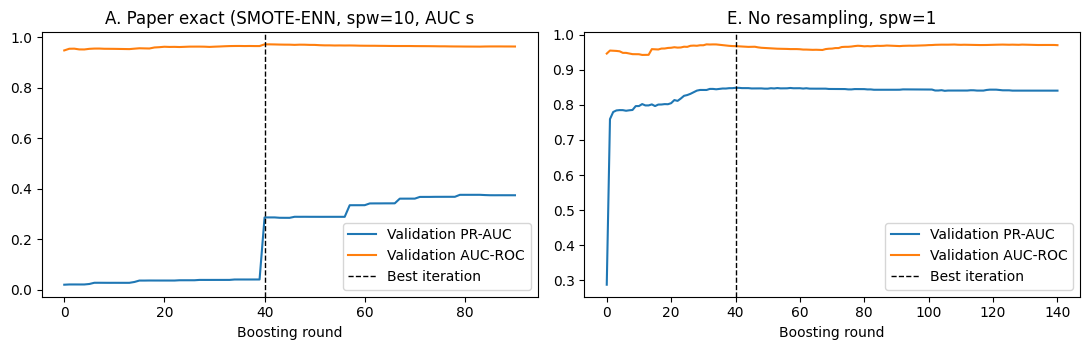

In [ ]:
BEST = val_table.iloc[0]['Config']
print("Selected:", BEST)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, name in enumerate([A, BEST]):
    ev = fitted[name].evals_result()['validation_0']
    ax[i].plot(ev['aucpr'], label='Validation PR-AUC')
    ax[i].plot(ev['auc'], label='Validation AUC-ROC')
    ax[i].axvline(fitted[name].best_iteration, color='k', ls='--', lw=1, label='Best iteration')
    ax[i].set_title(name[:40]); ax[i].set_xlabel('Boosting round'); ax[i].legend()
plt.tight_layout(); plt.savefig(f'{SAVE_DIR}/figure_8_learning_curves_paper_vs_best.png', dpi=200); plt.show()

In [ ]:
val_rows, rules_of = [], {}
for name in [A, BEST]:
    vp = fitted[name].predict_proba(Xva[feats_of[name]])[:, 1]
    rules_of[name] = threshold_rules(y_val, vp)
    for rule, t in rules_of[name].items():
        val_rows.append(evaluate(f'{name[:2]} {rule}', y_val, vp, t))

val_thr = pd.DataFrame(val_rows)
display(val_thr[['Model', 'Threshold', 'Precision', 'Recall', 'F1', 'FPR', 'Alerts_per_10k', 'Cost_usd']].round(4))

PRIMARY_RULE = 'F1-max'

,Model,Threshold,Precision,Recall,F1,FPR,Alerts_per_10k,Cost_usd
0,A. F1-max,0.8911,0.3623,0.7576,0.4902,0.0016,24.3198,2345.6
1,A. Cost-optimal,0.8911,0.3623,0.7576,0.4902,0.0016,24.3198,2345.6
2,E. F1-max,0.3841,0.9655,0.8485,0.9032,0.0000,10.2213,1402.4
3,E. Cost-optimal,0.3841,0.9655,0.8485,0.9032,0.0000,10.2213,1402.4
4,E. Precision>=0.5,0.0990,0.5000,0.8485,0.6292,0.0010,19.7378,1467.2
5,E. Precision>=0.8,0.2220,0.8000,0.8485,0.8235,0.0002,12.3361,1416.8
6,E. FPR<=0.1%,0.0990,0.5000,0.8485,0.6292,0.0010,19.7378,1467.2


In [ ]:
test_rows, test_proba_of = [], {}
for name in [A, BEST]:
    tp_ = fitted[name].predict_proba(Xte[feats_of[name]])[:, 1]
    test_proba_of[name] = tp_
    for rule, t in rules_of[name].items():
        test_rows.append(evaluate(f'{name[:2]} {rule}', y_te, tp_, t))

final = pd.DataFrame(test_rows)
final.loc[len(final)] = dict(Model='Paper (reported)', Threshold=0.32, Precision=0.95,
                             Recall=0.89, F1=0.92, AUC_ROC=0.98)
cols = ['Model', 'Threshold', 'Precision', 'Recall', 'F1', 'FPR', 'Alerts_per_10k',
        'AUC_ROC', 'PR_AUC', 'TP', 'FP', 'FN', 'Cost_usd']
display(final[cols].round(4))
final.to_csv(f'{SAVE_DIR}/table_11_final_test_results.csv', index=False)

,Model,Threshold,Precision,Recall,F1,FPR,Alerts_per_10k,AUC_ROC,PR_AUC,TP,FP,FN,Cost_usd
0,A. F1-max,0.8911,0.4583,0.7432,0.5670,0.0011,21.1469,0.9282,0.3475,55.0,65.0,19.0,5476.0
1,A. Cost-optimal,0.8911,0.4583,0.7432,0.5670,0.0011,21.1469,0.9282,0.3475,55.0,65.0,19.0,5476.0
2,E. F1-max,0.3841,0.8814,0.7027,0.7820,0.0001,10.3972,0.9822,0.7758,52.0,7.0,22.0,6176.8
3,E. Cost-optimal,0.3841,0.8814,0.7027,0.7820,0.0001,10.3972,0.9822,0.7758,52.0,7.0,22.0,6176.8
4,E. Precision>=0.5,0.0990,0.5463,0.7973,0.6484,0.0009,19.0322,0.9822,0.7758,59.0,49.0,15.0,4317.6
5,E. Precision>=0.8,0.2220,0.6707,0.7432,0.7051,0.0005,14.4504,0.9822,0.7758,55.0,27.0,19.0,5384.8
6,E. FPR<=0.1%,0.0990,0.5463,0.7973,0.6484,0.0009,19.0322,0.9822,0.7758,59.0,49.0,15.0,4317.6
7,Paper (reported),0.3200,0.9500,0.8900,0.9200,NaN,NaN,0.9800,NaN,NaN,NaN,NaN,NaN


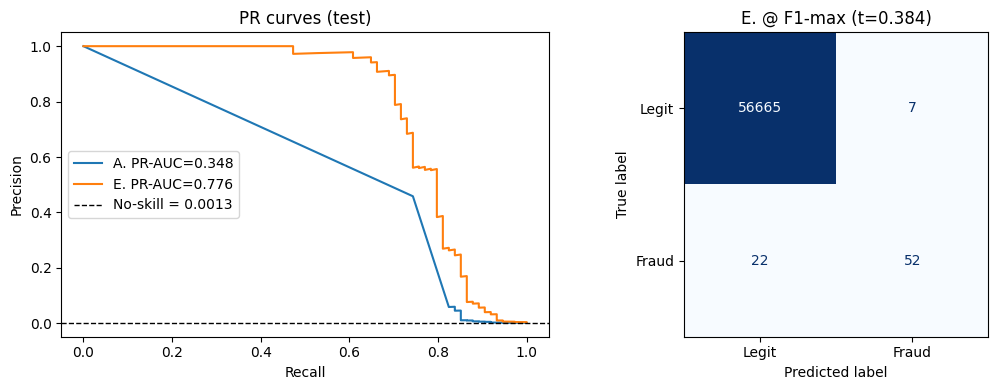

In [ ]:
t_best = rules_of[BEST][PRIMARY_RULE]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name in [A, BEST]:
    p, r, _ = precision_recall_curve(y_te, test_proba_of[name])
    ax[0].plot(r, p, label=f"{name[:2]} PR-AUC={average_precision_score(y_te, test_proba_of[name]):.3f}")
ax[0].axhline(y_te.mean(), color='k', ls='--', lw=1, label=f'No-skill = {y_te.mean():.4f}')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('PR curves (test)'); ax[0].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, (test_proba_of[BEST] >= t_best).astype(int)),
                       display_labels=['Legit', 'Fraud']).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title(f'{BEST[:2]} @ {PRIMARY_RULE} (t={t_best:.3f})')
plt.tight_layout(); plt.savefig(f'{SAVE_DIR}/figure_9_test_paper_vs_best.png', dpi=200); plt.show()

FP: 7 | FN: 22
Median amount FP: 11.32 | FN: 14.850000000000001 | all legit: 18.045
FPs with Amount > 5000: 14.29 % (paper claims 63%)
Single-transaction latency: 12.82 ms (paper: 12 ms)


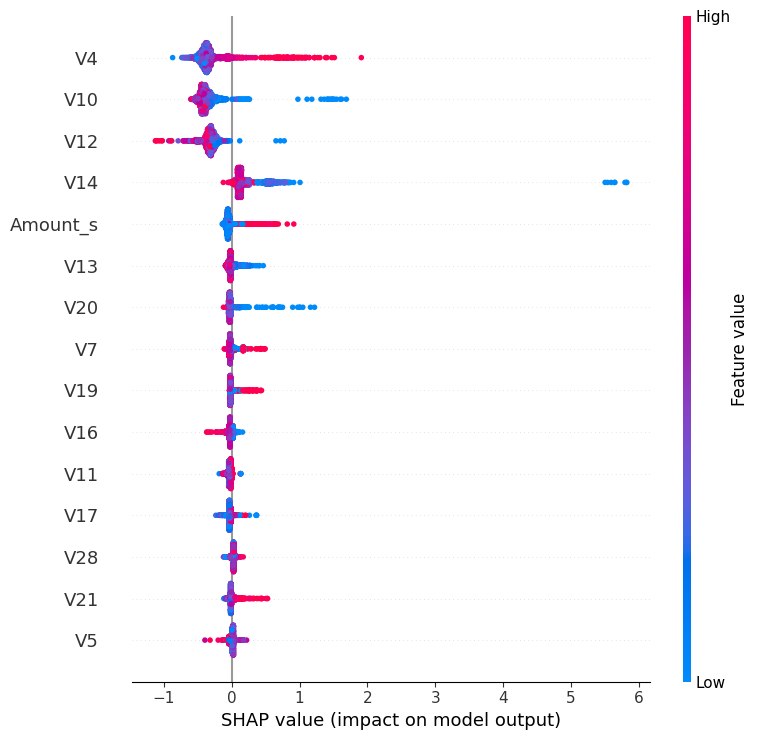

Saved to Drive


In [ ]:
import shap
bm, bf = fitted[BEST], feats_of[BEST]
pred = (test_proba_of[BEST] >= t_best).astype(int)

err = X_te[['Amount', 'Hour']].copy()
err['y'] = y_te.values; err['pred'] = pred
fp_df = err[(err.pred == 1) & (err.y == 0)]; fn_df = err[(err.pred == 0) & (err.y == 1)]
print(f"FP: {len(fp_df)} | FN: {len(fn_df)}")
print("Median amount FP:", fp_df.Amount.median(), "| FN:", fn_df.Amount.median(),
      "| all legit:", err[err.y == 0].Amount.median())
print("FPs with Amount > 5000:", round((fp_df.Amount > 5000).mean() * 100, 2), "% (paper claims 63%)")

one = Xte[bf].iloc[[0]]; bm.predict_proba(one)
t0 = time.perf_counter()
for _ in range(500): bm.predict_proba(one)
print(f"Single-transaction latency: {(time.perf_counter() - t0) / 500 * 1000:.2f} ms (paper: 12 ms)")

sample = Xte[bf].sample(2000, random_state=SEED)
shap.summary_plot(shap.TreeExplainer(bm).shap_values(sample), sample, max_display=15, show=False)
plt.tight_layout(); plt.savefig(f'{SAVE_DIR}/figure_10_shap_best.png', dpi=200); plt.show()

bm.save_model(f'{SAVE_DIR}/xgb_best_model.json')
joblib.dump({'amount_scaler': scaler, 'hour_scaler': hour_scaler, 'features': bf,
             'threshold': t_best, 'rule': PRIMARY_RULE, 'config': BEST},
            f'{SAVE_DIR}/preprocessing_best.joblib')
print("Saved to Drive")

In [ ]:
!pip install -q xgboost imbalanced-learn optuna shap

import os, sys, time, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb, optuna, shap
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import EditedNearestNeighbours, RandomUnderSampler

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
SEED = 42
np.random.seed(SEED)

N_TRIALS    = int(os.environ.get('N_TRIALS', 100))
TIMEOUT_MIN = int(os.environ.get('TIMEOUT_MIN', 60))
N_SPLITS    = 5
RESET_STUDY = False
FP_COST, FN_COST = 2.40, 280.0

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/CloudAI_CW1'
else:
    SAVE_DIR = os.environ.get('SAVE_DIR', './CloudAI_CW1')
FIG_DIR, TAB_DIR = f'{SAVE_DIR}/figures', f'{SAVE_DIR}/tables'
for d in (SAVE_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)
print('XGBoost', xgb.__version__, '| Optuna', optuna.__version__, '| saving to', SAVE_DIR)

Mounted at /content/drive
XGBoost 3.4.1 | Optuna 5.0.0 | saving to /content/drive/MyDrive/CloudAI_CW1


In [ ]:

def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=200); plt.show()

def savetab(df, name, index=False):
    df.to_csv(f'{TAB_DIR}/{name}.csv', index=index)

def evaluate(name, y_true, proba, t):
    """All metrics for one model at one threshold."""
    y_true = np.asarray(y_true); pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(Model=name, Threshold=round(float(t), 4),
                Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                FPR=fp / (fp + tn), Alerts_per_10k=(tp + fp) / len(y_true) * 1e4,
                AUC_ROC=roc_auc_score(y_true, proba), PR_AUC=average_precision_score(y_true, proba),
                TP=tp, FP=fp, FN=fn, TN=tn, Cost_usd=fp * FP_COST + fn * FN_COST)

def threshold_rules(y_true, proba, precision_targets=(0.5, 0.8)):
    """Candidate thresholds, chosen on NON-test data only. No Youden's J."""
    y_true = np.asarray(y_true)
    p, r, th = precision_recall_curve(y_true, proba)
    p, r = p[:-1], r[:-1]
    P = y_true.sum(); N = len(y_true) - P
    tp = r * P
    fp = np.where(p > 0, tp / np.maximum(p, 1e-12) - tp, 0)
    f1 = 2 * p * r / (p + r + 1e-12)
    cost = fp * FP_COST + (P - tp) * FN_COST
    rules = {'F1-max': th[np.argmax(f1)], 'Cost-optimal': th[np.argmin(cost)]}
    for target in precision_targets:
        ok = np.where(p >= target)[0]
        if len(ok):
            rules[f'Precision>={target}'] = th[ok[np.argmax(r[ok])]]
    ok = np.where(fp / N <= 0.001)[0]
    if len(ok):
        rules['FPR<=0.1%'] = th[ok[np.argmax(r[ok])]]
    return {k: float(v) for k, v in rules.items()}

#Feature set

In [ ]:
for d in (X_tr, X_val, X_te):
    d['Hour'] = (d['Time'] // 3600) % 24
hour_scaler = StandardScaler().fit(X_tr[['Hour']])
for d in (X_tr, X_val, X_te):
    d['Hour_s'] = hour_scaler.transform(d[['Hour']]).ravel()

F_ALL    = [f'V{i}' for i in range(1, 29)] + ['Amount_s', 'Hour_s']
F_NOHOUR = [f for f in F_ALL if f != 'Hour_s']
FEATURES = F_ALL
Xtr, Xva, Xte = X_tr[F_ALL], X_val[F_ALL], X_te[F_ALL]
print(Xtr.shape, Xva.shape, Xte.shape)
print('Frauds  train:', y_tr.sum(), '| val:', y_val.sum(), '| test:', y_te.sum())   # expected 366 / 33 / 74

(198608, 30) (28372, 30) (56746, 30)
Frauds  train: 366 | val: 33 | test: 74


#SMOTE-ENN: load from Drive

In [ ]:
SMOTEENN_PATH = f'{SAVE_DIR}/train_smoteenn.joblib'
X_res = None
if os.path.exists(SMOTEENN_PATH):
    X_res, y_res = joblib.load(SMOTEENN_PATH)
    X_res = pd.DataFrame(np.asarray(X_res), columns=F_ALL); y_res = pd.Series(np.asarray(y_res))
    if (y_res == 1).sum() != (y_tr == 0).sum():           # cached file does not match this split
        print('Cached file does not match the current split - recomputing'); X_res = None
    else:
        print('Loaded cached SMOTE-ENN data:', X_res.shape, np.bincount(y_res))
if X_res is None:
    t0 = time.time()
    X_res, y_res = SMOTEENN(smote=SMOTE(random_state=SEED),
                            enn=EditedNearestNeighbours(sampling_strategy='all', n_jobs=-1),
                            random_state=SEED).fit_resample(Xtr, y_tr)
    X_res = pd.DataFrame(np.asarray(X_res), columns=F_ALL); y_res = pd.Series(np.asarray(y_res))
    joblib.dump((X_res, y_res), SMOTEENN_PATH)
    print(f'SMOTE-ENN done in {(time.time() - t0) / 60:.1f} min ->', np.bincount(y_res))

removed = 2 * (y_tr == 0).sum() - len(y_res)
smoteenn_tbl = pd.DataFrame({'Legitimate': [(y_tr == 0).sum(), (y_res == 0).sum()],
                             'Fraudulent': [y_tr.sum(), (y_res == 1).sum()]},
                            index=['Original train', 'After SMOTE-ENN'])
smoteenn_tbl['Fraud rate %'] = smoteenn_tbl.Fraudulent / smoteenn_tbl.sum(axis=1) * 100
print(smoteenn_tbl)
print(f'ENN removed {removed} of {2 * (y_tr == 0).sum()} samples ({removed / (2 * (y_tr == 0).sum()):.2%})')
savetab(smoteenn_tbl, 'table_5_smoteenn_distribution', index=True)

Loaded cached SMOTE-ENN data: (396148, 30) [197906 198242]
                 Legitimate  Fraudulent  Fraud rate %
Original train       198242         366      0.184283
After SMOTE-ENN      197906      198242     50.042408
ENN removed 336 of 396484 samples (0.08%)


#Ablation: paper config vs alternatives (validation)

In [ ]:
ratio = (y_tr == 0).sum() / y_tr.sum()
X_sm10, y_sm10 = SMOTE(sampling_strategy=0.1, random_state=SEED).fit_resample(Xtr, y_tr)
sq = np.sqrt(ratio)

base  = dict(max_depth=6, learning_rate=0.05, n_estimators=2000, eval_metric=['auc', 'aucpr'],
             early_stopping_rounds=100, tree_method='hist', random_state=SEED, n_jobs=-1)
paper = dict(learning_rate=0.01, n_estimators=500, scale_pos_weight=10,
             eval_metric=['aucpr', 'auc'], early_stopping_rounds=50)      # last metric (AUC-ROC) drives stopping
reg   = dict(max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=5)

configs = {
    'A. Paper exact (SMOTE-ENN, spw=10, AUC stop)': (X_res,  y_res,  F_ALL,    paper),
    'B. Paper + PR-AUC stopping':                   (X_res,  y_res,  F_ALL,    dict(learning_rate=0.01, scale_pos_weight=10)),
    'C. SMOTE-ENN 1:1, spw=1':                      (X_res,  y_res,  F_ALL,    dict(scale_pos_weight=1)),
    'D. SMOTE 1:10, spw=1':                         (X_sm10, y_sm10, F_ALL,    dict(scale_pos_weight=1)),
    'E. No resampling, spw=1':                      (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=1)),
    'F. No resampling, spw=sqrt(ratio)':            (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=sq)),
    'G. F + regularisation':                        (Xtr,    y_tr,   F_ALL,    dict(scale_pos_weight=sq, **reg)),
    'H. F without Hour':                            (Xtr,    y_tr,   F_NOHOUR, dict(scale_pos_weight=sq)),
}
rows, fitted, feats_of = [], {}, {}
for name, (Xa, ya, feats, extra) in configs.items():
    t0 = time.time()
    m = xgb.XGBClassifier(**{**base, **extra})
    m.fit(Xa[feats], ya, eval_set=[(Xva[feats], y_val)], verbose=0)
    vp = m.predict_proba(Xva[feats])[:, 1]
    rows.append(dict(Config=name, Val_PR_AUC=average_precision_score(y_val, vp), Val_AUC_ROC=roc_auc_score(y_val, vp),
                     Best_iter=m.best_iteration, Max_iter=m.n_estimators, Train_s=round(time.time() - t0)))
    fitted[name], feats_of[name] = m, feats
    print(f'done: {name} ({rows[-1]["Train_s"]}s)')
val_table = pd.DataFrame(rows).sort_values('Val_PR_AUC', ascending=False)
display(val_table.round(4)); savetab(val_table, 'table_6_ablation_validation')

done: A. Paper exact (SMOTE-ENN, spw=10, AUC stop) (23s)
done: B. Paper + PR-AUC stopping (30s)
done: C. SMOTE-ENN 1:1, spw=1 (15s)
done: D. SMOTE 1:10, spw=1 (11s)
done: E. No resampling, spw=1 (6s)
done: F. No resampling, spw=sqrt(ratio) (16s)
done: G. F + regularisation (8s)
done: H. F without Hour (17s)


,Config,Val_PR_AUC,Val_AUC_ROC,Best_iter,Max_iter,Train_s
4,"E. No resampling, spw=1",0.8487,0.9674,40,2000,6
6,G. F + regularisation,0.8324,0.9751,90,2000,8
7,H. F without Hour,0.8304,0.9836,381,2000,17
5,"F. No resampling, spw=sqrt(ratio)",0.8303,0.9767,333,2000,16
3,"D. SMOTE 1:10, spw=1",0.7946,0.9733,117,2000,11
2,"C. SMOTE-ENN 1:1, spw=1",0.7934,0.9636,113,2000,15
1,B. Paper + PR-AUC stopping,0.7680,0.9600,246,2000,30
0,"A. Paper exact (SMOTE-ENN, spw=10, AUC stop)",0.2815,0.9725,40,500,23


Paper model best iteration: 40
Starting score (base_score): [8.3711594E-1] | weighted fraud share in training: 0.909
Validation LEGIT transactions scored >= 0.5: 100.0%


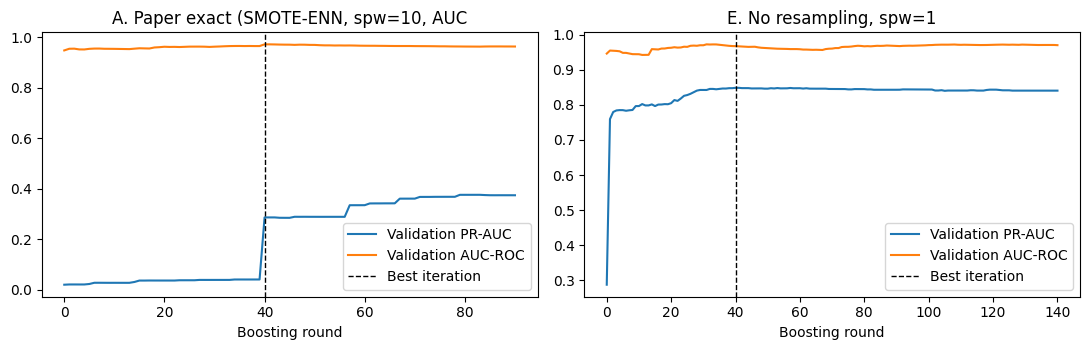

In [ ]:
# why the paper's configuration flags almost everything
A, E = 'A. Paper exact (SMOTE-ENN, spw=10, AUC stop)', 'E. No resampling, spw=1'
pa = fitted[A]
base_score = json.loads(pa.get_booster().save_config())['learner']['learner_model_param']['base_score']
w_share = 10 * (y_res == 1).sum() / (10 * (y_res == 1).sum() + (y_res == 0).sum())
vp_a = pa.predict_proba(Xva)[:, 1]
print('Paper model best iteration:', pa.best_iteration)
print('Starting score (base_score):', base_score, f'| weighted fraud share in training: {w_share:.3f}')
print(f'Validation LEGIT transactions scored >= 0.5: {(vp_a[y_val.values == 0] >= 0.5).mean():.1%}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, name in enumerate([A, E]):
    ev = fitted[name].evals_result()['validation_0']
    ax[i].plot(ev['aucpr'], label='Validation PR-AUC'); ax[i].plot(ev['auc'], label='Validation AUC-ROC')
    ax[i].axvline(fitted[name].best_iteration, color='k', ls='--', lw=1, label='Best iteration')
    ax[i].set_title(name[:38]); ax[i].set_xlabel('Boosting round'); ax[i].legend()
savefig('figure_5_learning_curves_paper_vs_E')

In [ ]:
# Validation thresholds for the two reference models (used in the final test comparison)
ref_thr = {}
for name in [A, E]:
    vp = fitted[name].predict_proba(Xva[feats_of[name]])[:, 1]
    ref_thr[name] = threshold_rules(y_val, vp)['F1-max']
print({k[:2]: round(v, 4) for k, v in ref_thr.items()})

{'A.': 0.8911, 'E.': 0.3841}


In [ ]:
Xtv = pd.concat([Xtr, Xva]).reset_index(drop=True)
ytv = pd.concat([y_tr, y_val]).reset_index(drop=True)
folds = list(TimeSeriesSplit(n_splits=N_SPLITS).split(Xtv))
fold_info = pd.DataFrame([dict(Fold=k, Train_rows=len(a), Train_frauds=int(ytv.iloc[a].sum()),
                               Test_rows=len(b), Test_frauds=int(ytv.iloc[b].sum()))
                          for k, (a, b) in enumerate(folds)])
print(fold_info); savetab(fold_info, 'table_7_cv_folds')

FIXED = dict(tree_method='hist', eval_metric='aucpr', random_state=SEED, n_jobs=-1)

def make_params(p):
    params = {**FIXED, **{k: v for k, v in p.items() if k != 'use_hour'}}
    return params, (F_ALL if p.get('use_hour', True) else F_NOHOUR)

def run_cv(params, feats, trial=None, return_oof=False):
    scores, oof = [], np.full(len(ytv), np.nan)
    for k, (a, b) in enumerate(folds):
        m = xgb.XGBClassifier(**params).fit(Xtv.iloc[a][feats], ytv.iloc[a])
        p = m.predict_proba(Xtv.iloc[b][feats])[:, 1]
        oof[b] = p
        scores.append(average_precision_score(ytv.iloc[b], p))
        if trial is not None:
            trial.report(float(np.mean(scores)), k)
            if trial.should_prune():
                raise optuna.TrialPruned()
    out = dict(mean=float(np.mean(scores)), std=float(np.std(scores)), folds=scores)
    if return_oof:
        out['oof'] = oof
    return out

def objective(trial):
    p = dict(
        n_estimators     = trial.suggest_int('n_estimators', 50, 1000, step=50),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        max_depth        = trial.suggest_int('max_depth', 3, 8),
        min_child_weight = trial.suggest_float('min_child_weight', 1, 20, log=True),
        subsample        = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree = trial.suggest_float('colsample_bytree', 0.4, 1.0),
        gamma            = trial.suggest_float('gamma', 0.0, 5.0),
        reg_lambda       = trial.suggest_float('reg_lambda', 1e-3, 20, log=True),
        reg_alpha        = trial.suggest_float('reg_alpha', 1e-3, 5, log=True),
        scale_pos_weight = trial.suggest_float('scale_pos_weight', 1, 50, log=True),
        max_delta_step   = trial.suggest_int('max_delta_step', 0, 5),
        use_hour         = trial.suggest_categorical('use_hour', [True, False]),
    )
    params, feats = make_params(p)
    res = run_cv(params, feats, trial=trial)
    trial.set_user_attr('cv_std', res['std'])
    trial.set_user_attr('fold_scores', [round(s, 4) for s in res['folds']])
    return res['mean']

# Known-good starting points from the ablation (E and F)
E_START = dict(n_estimators=50, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=1.0,
               colsample_bytree=1.0, gamma=0.0, reg_lambda=1.0, reg_alpha=1e-3, scale_pos_weight=1.0,
               max_delta_step=0, use_hour=True)
F_START = {**E_START, 'n_estimators': 350, 'scale_pos_weight': float(sq)}

   Fold  Train_rows  Train_frauds  Test_rows  Test_frauds
0     0       37830           103      37830           81
1     1       75660           184      37830           52
2     2      113490           236      37830           73
3     3      151320           309      37830           43
4     4      189150           352      37830           47


In [ ]:
STUDY_PATH = f'{SAVE_DIR}/optuna_study.joblib'
if os.path.exists(STUDY_PATH) and not RESET_STUDY:
    study = joblib.load(STUDY_PATH)
    print(f'Resuming saved study with {len(study.trials)} trials')
else:
    study = optuna.create_study(direction='maximize', study_name='xgb_fraud',
                                sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1))
    study.enqueue_trial(E_START); study.enqueue_trial(F_START)

def progress(study, trial):
    joblib.dump(study, STUDY_PATH)
    if trial.state == optuna.trial.TrialState.COMPLETE:
        print(f'Trial {trial.number:3d} | CV PR-AUC {trial.value:.4f} ± {trial.user_attrs["cv_std"]:.3f} '
              f'| best so far {study.best_value:.4f} | {trial.duration.total_seconds():.0f}s')
    else:
        print(f'Trial {trial.number:3d} | {trial.state.name}')

done = len([t for t in study.trials if t.state.is_finished()])
remaining = max(0, N_TRIALS - done)
print(f'Running {remaining} more trials (limit {TIMEOUT_MIN} min)')
t0 = time.time()
if remaining:
    study.optimize(objective, n_trials=remaining, timeout=TIMEOUT_MIN * 60, callbacks=[progress], gc_after_trial=True)
print(f'Finished in {(time.time() - t0) / 60:.1f} min | best CV PR-AUC = {study.best_value:.4f}')
print('Best hyperparameters:'); print(json.dumps(study.best_params, indent=2))

Running 100 more trials (limit 60 min)
Trial   0 | CV PR-AUC 0.7399 ± 0.100 | best so far 0.7399 | 21s
Trial   1 | CV PR-AUC 0.8058 ± 0.023 | best so far 0.8058 | 36s
Trial   2 | CV PR-AUC 0.7981 ± 0.018 | best so far 0.8058 | 29s
Trial   3 | CV PR-AUC 0.7962 ± 0.021 | best so far 0.8058 | 16s
Trial   4 | CV PR-AUC 0.7975 ± 0.021 | best so far 0.8058 | 20s
Trial   5 | CV PR-AUC 0.7948 ± 0.021 | best so far 0.8058 | 33s
Trial   6 | CV PR-AUC 0.7759 ± 0.027 | best so far 0.8058 | 55s
Trial   7 | CV PR-AUC 0.8019 ± 0.018 | best so far 0.8058 | 48s
Trial   8 | CV PR-AUC 0.8079 ± 0.022 | best so far 0.8079 | 36s
Trial   9 | PRUNED
Trial  10 | CV PR-AUC 0.8043 ± 0.020 | best so far 0.8079 | 54s
Trial  11 | PRUNED
Trial  12 | CV PR-AUC 0.8045 ± 0.021 | best so far 0.8079 | 28s
Trial  13 | CV PR-AUC 0.8047 ± 0.022 | best so far 0.8079 | 30s
Trial  14 | CV PR-AUC 0.8067 ± 0.019 | best so far 0.8079 | 28s
Trial  15 | CV PR-AUC 0.8100 ± 0.023 | best so far 0.8100 | 60s
Trial  16 | CV PR-AUC 0.804

,number,value,params_colsample_bytree,params_gamma,params_learning_rate,params_max_delta_step,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_scale_pos_weight,params_subsample,params_use_hour,user_attrs_cv_std,user_attrs_fold_scores,state
88,88,0.8142,0.5079,0.6450,0.0198,5,8,2.6510,650,1.3435,0.0027,39.0958,0.5846,True,0.0197,"[0.8138, 0.8293, 0.8079, 0.8385, 0.7814]",COMPLETE
58,58,0.8135,0.4694,0.8068,0.0182,5,8,3.7496,650,1.2012,0.0055,39.8023,0.5465,True,0.0226,"[0.8143, 0.8293, 0.8091, 0.8407, 0.7743]",COMPLETE
83,83,0.8131,0.4206,0.3879,0.0186,5,8,3.2352,700,0.7510,0.0094,41.6213,0.5552,True,0.0180,"[0.8132, 0.8293, 0.8096, 0.8318, 0.7816]",COMPLETE
37,37,0.8128,0.4213,1.0768,0.0223,5,8,4.1074,600,1.0434,0.0180,23.8436,0.5974,True,0.0194,"[0.8126, 0.8281, 0.8075, 0.8359, 0.7797]",COMPLETE
92,92,0.8126,0.4458,0.3989,0.0235,5,8,2.1816,700,0.8415,0.0031,37.4949,0.5889,True,0.0162,"[0.815, 0.8277, 0.8073, 0.8287, 0.7846]",COMPLETE
77,77,0.8126,0.4814,0.5788,0.0241,5,8,3.0444,650,1.1759,0.0045,47.8018,0.5967,True,0.0175,"[0.8167, 0.8299, 0.8019, 0.8301, 0.7844]",COMPLETE
91,91,0.8125,0.5356,0.4817,0.0212,5,8,2.2099,700,1.1467,0.0036,40.2246,0.5859,True,0.0197,"[0.817, 0.8283, 0.8022, 0.8349, 0.78]",COMPLETE
89,89,0.8119,0.4712,0.3383,0.0265,5,8,2.6405,700,0.7963,0.0035,47.6238,0.6638,True,0.0191,"[0.815, 0.8294, 0.7938, 0.8349, 0.7862]",COMPLETE
30,30,0.8114,0.4724,1.7818,0.0189,4,8,3.2046,550,2.7728,0.0141,41.4749,0.6044,True,0.0196,"[0.8148, 0.8294, 0.8072, 0.8295, 0.7761]",COMPLETE
38,38,0.8114,0.4756,1.1310,0.0160,4,8,4.2532,600,1.0635,0.0029,28.9284,0.5482,True,0.0239,"[0.8131, 0.8292, 0.8027, 0.8405, 0.7714]",COMPLETE


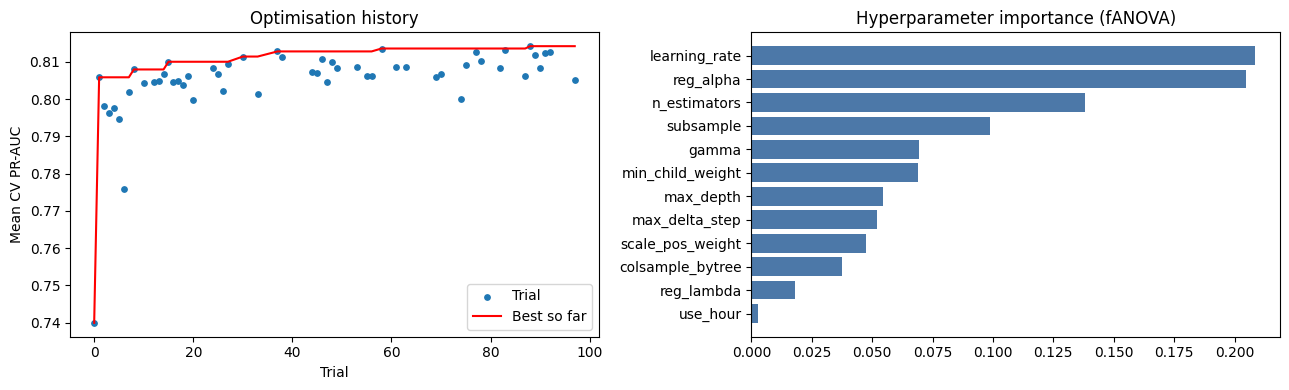

In [ ]:
# Table 8: top trials, Figure 6: optimisation history and parameter importance
trials_df = study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs', 'state'))
top = trials_df[trials_df.state == 'COMPLETE'].sort_values('value', ascending=False).head(10)
display(top.round(4)); savetab(trials_df, 'table_8_optuna_trials')

complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vals = [t.value for t in complete]; nums = [t.number for t in complete]
ax[0].scatter(nums, vals, s=15, label='Trial'); ax[0].plot(nums, np.maximum.accumulate(vals), 'r-', label='Best so far')
ax[0].set_xlabel('Trial'); ax[0].set_ylabel('Mean CV PR-AUC'); ax[0].set_title('Optimisation history'); ax[0].legend()
try:
    imp = optuna.importance.get_param_importances(study)
    ax[1].barh(list(imp.keys())[::-1], list(imp.values())[::-1], color='#4C78A8')
    ax[1].set_title('Hyperparameter importance (fANOVA)')
except Exception as e:
    ax[1].text(0.1, 0.5, f'Importance not available: {e}'); ax[1].axis('off')
savefig('figure_6_optuna_history_importance')

In [ ]:
# Table 9: untuned vs tuned on the same CV folds (E and F use the starting values above)
best_params, best_feats = make_params(study.best_params)
cv_rows, cv_oof = [], {}
for name, p in [('E (untuned, spw=1)', E_START), ('F (untuned, spw=sqrt(ratio))', F_START), ('Tuned (Optuna best)', study.best_params)]:
    params, feats = make_params(p)
    r = run_cv(params, feats, return_oof=True)
    cv_oof[name] = r['oof']
    cv_rows.append(dict(Model=name, CV_PR_AUC_mean=r['mean'], CV_PR_AUC_std=r['std'],
                        **{f'Fold_{k}': s for k, s in enumerate(r['folds'])}))
cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(4)); savetab(cv_table, 'table_9_cv_untuned_vs_tuned')

,Model,CV_PR_AUC_mean,CV_PR_AUC_std,Fold_0,Fold_1,Fold_2,Fold_3,Fold_4
0,"E (untuned, spw=1)",0.7399,0.1005,0.7985,0.8185,0.7682,0.5424,0.7721
1,"F (untuned, spw=sqrt(ratio))",0.8058,0.0233,0.8082,0.8309,0.7857,0.8308,0.7735
2,Tuned (Optuna best),0.8142,0.0197,0.8138,0.8293,0.8079,0.8385,0.7814


In [ ]:
oof = cv_oof['Tuned (Optuna best)']
mask = ~np.isnan(oof)
y_oof, p_oof = ytv.values[mask], oof[mask]
print(f'Out-of-fold predictions: {mask.sum()} transactions, {y_oof.sum()} frauds')

tuned_rules = threshold_rules(y_oof, p_oof)
oof_thr = pd.DataFrame([evaluate(rule, y_oof, p_oof, t) for rule, t in tuned_rules.items()])
display(oof_thr[['Model', 'Threshold', 'Precision', 'Recall', 'F1', 'FPR', 'Alerts_per_10k', 'Cost_usd']].round(4))
savetab(oof_thr, 'table_10_thresholds_oof')

per_fold = []
for k, (a, b) in enumerate(folds):
    t = threshold_rules(ytv.values[b], oof[b])['F1-max']
    per_fold.append(dict(Fold=k, Frauds=int(ytv.values[b].sum()), F1_max_threshold=round(t, 4)))
print(pd.DataFrame(per_fold))

PRIMARY_RULE = 'F1-max'

Out-of-fold predictions: 189150 transactions, 296 frauds


,Model,Threshold,Precision,Recall,F1,FPR,Alerts_per_10k,Cost_usd
0,F1-max,0.4340,0.8593,0.7838,0.8198,0.0002,14.2744,18011.2
1,Cost-optimal,0.0530,0.5718,0.8345,0.6786,0.0010,22.8390,14164.0
2,Precision>=0.5,0.0356,0.5000,0.8345,0.6253,0.0013,26.1168,14312.8
3,Precision>=0.8,0.2122,0.8007,0.8142,0.8074,0.0003,15.9133,15544.0
4,FPR<=0.1%,0.0521,0.5678,0.8345,0.6758,0.0010,22.9976,14171.2


   Fold  Frauds  F1_max_threshold
0     0      81            0.2175
1     1      52            0.3097
2     2      73            0.4600
3     3      43            0.8435
4     4      47            0.8496


In [ ]:
t0 = time.time()
final_model = xgb.XGBClassifier(**best_params).fit(Xtv[best_feats], ytv)
print(f'Final model trained in {time.time() - t0:.1f}s on {len(ytv)} transactions, features: {len(best_feats)}')

proba = {'A. Paper exact': fitted[A].predict_proba(Xte[feats_of[A]])[:, 1],
         'E. No resampling (untuned)': fitted[E].predict_proba(Xte[feats_of[E]])[:, 1],
         'Tuned XGBoost': final_model.predict_proba(Xte[best_feats])[:, 1]}

test_rows = [evaluate('A. Paper exact @F1-max(val)', y_te, proba['A. Paper exact'], ref_thr[A]),
             evaluate('E. Untuned @F1-max(val)', y_te, proba['E. No resampling (untuned)'], ref_thr[E])]
for rule, t in tuned_rules.items():
    test_rows.append(evaluate(f'Tuned @{rule}(OOF)', y_te, proba['Tuned XGBoost'], t))
final = pd.DataFrame(test_rows)
final.loc[len(final)] = dict(Model='Paper (reported)', Threshold=0.32, Precision=0.95, Recall=0.89, F1=0.92, AUC_ROC=0.98)
cols = ['Model', 'Threshold', 'Precision', 'Recall', 'F1', 'FPR', 'Alerts_per_10k', 'AUC_ROC', 'PR_AUC', 'TP', 'FP', 'FN', 'Cost_usd']
display(final[cols].round(4)); savetab(final, 'table_11_final_test_results')

Final model trained in 28.2s on 226980 transactions, features: 30


,Model,Threshold,Precision,Recall,F1,FPR,Alerts_per_10k,AUC_ROC,PR_AUC,TP,FP,FN,Cost_usd
0,A. Paper exact @F1-max(val),0.8911,0.4583,0.7432,0.5670,0.0011,21.1469,0.9282,0.3475,55.0,65.0,19.0,5476.0
1,E. Untuned @F1-max(val),0.3841,0.8814,0.7027,0.7820,0.0001,10.3972,0.9822,0.7758,52.0,7.0,22.0,6176.8
2,Tuned @F1-max(OOF),0.4340,0.8485,0.7568,0.8000,0.0002,11.6308,0.9879,0.8052,56.0,10.0,18.0,5064.0
3,Tuned @Cost-optimal(OOF),0.0530,0.6344,0.7973,0.7066,0.0006,16.3888,0.9879,0.8052,59.0,34.0,15.0,4281.6
4,Tuned @Precision>=0.5(OOF),0.0356,0.5364,0.7973,0.6413,0.0009,19.3846,0.9879,0.8052,59.0,51.0,15.0,4322.4
5,Tuned @Precision>=0.8(OOF),0.2122,0.8143,0.7703,0.7917,0.0002,12.3357,0.9879,0.8052,57.0,13.0,17.0,4791.2
6,Tuned @FPR<=0.1%(OOF),0.0521,0.6211,0.7973,0.6982,0.0006,16.7413,0.9879,0.8052,59.0,36.0,15.0,4286.4
7,Paper (reported),0.3200,0.9500,0.8900,0.9200,NaN,NaN,0.9800,NaN,NaN,NaN,NaN,NaN


In [ ]:
# 95% bootstrap confidence intervals on the test set (only 74 test frauds, so uncertainty is large)
def bootstrap_ci(y, p, t, n=1000):
    rng = np.random.default_rng(SEED); y = np.asarray(y); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); yi, pi = y[i], p[i]
        if yi.sum() == 0: continue
        pred = pi >= t; tp = (pred & (yi == 1)).sum(); fp = (pred & (yi == 0)).sum()
        prec = tp / max(tp + fp, 1); rec = tp / yi.sum()
        out.append([prec, rec, 2 * prec * rec / max(prec + rec, 1e-12), average_precision_score(yi, pi)])
    out = np.array(out)
    return pd.DataFrame({'Mean': out.mean(0), 'CI_2.5%': np.percentile(out, 2.5, 0), 'CI_97.5%': np.percentile(out, 97.5, 0)},
                        index=['Precision', 'Recall', 'F1', 'PR_AUC'])
ci = bootstrap_ci(y_te, proba['Tuned XGBoost'], tuned_rules[PRIMARY_RULE])
print(f'Tuned model @ {PRIMARY_RULE}:'); display(ci.round(3)); savetab(ci, 'table_12_test_bootstrap_ci', index=True)

Tuned model @ F1-max:


,Mean,CI_2.5%,CI_97.5%
Precision,0.849,0.764,0.929
Recall,0.757,0.658,0.852
F1,0.799,0.724,0.870
PR_AUC,0.805,0.721,0.882


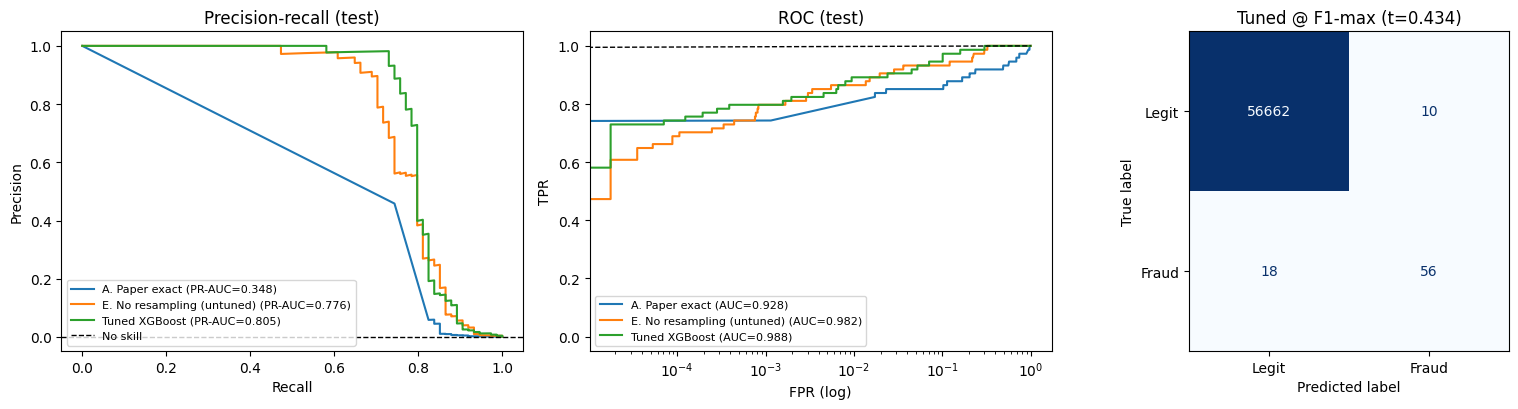

In [ ]:
# Figure 7: PR curves, ROC curves and confusion matrix
t_best = tuned_rules[PRIMARY_RULE]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, p in proba.items():
    pr, rc, _ = precision_recall_curve(y_te, p); fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(rc, pr, label=f'{name} (PR-AUC={average_precision_score(y_te, p):.3f})')
    ax[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_te, p):.3f})')
ax[0].axhline(y_te.mean(), color='k', ls='--', lw=1, label='No skill')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision'); ax[0].set_title('Precision-recall (test)'); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set_xscale('log'); ax[1].set_xlabel('FPR (log)'); ax[1].set_ylabel('TPR')
ax[1].set_title('ROC (test)'); ax[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_te, (proba['Tuned XGBoost'] >= t_best).astype(int)),
                       display_labels=['Legit', 'Fraud']).plot(ax=ax[2], cmap='Blues', colorbar=False)
ax[2].set_title(f'Tuned @ {PRIMARY_RULE} (t={t_best:.3f})')
savefig('figure_7_test_evaluation')

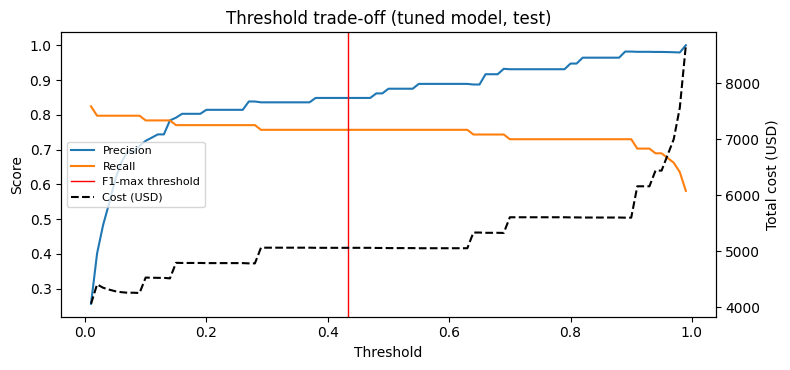

In [ ]:
# Figure 8: precision, recall and cost across thresholds for the tuned model
ths = np.linspace(0.01, 0.99, 99); p_t = proba['Tuned XGBoost']; yv = y_te.values
prec = [precision_score(yv, p_t >= t, zero_division=0) for t in ths]
rec  = [recall_score(yv, p_t >= t) for t in ths]
cost = [((p_t >= t) & (yv == 0)).sum() * FP_COST + ((p_t < t) & (yv == 1)).sum() * FN_COST for t in ths]
fig, ax1 = plt.subplots(figsize=(8, 3.8)); ax2 = ax1.twinx()
ax1.plot(ths, prec, label='Precision'); ax1.plot(ths, rec, label='Recall'); ax1.set_xlabel('Threshold'); ax1.set_ylabel('Score')
ax2.plot(ths, cost, 'k--', label='Cost (USD)'); ax2.set_ylabel('Total cost (USD)')
ax1.axvline(t_best, color='r', lw=1, label=f'{PRIMARY_RULE} threshold')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center left', fontsize=8); ax1.set_title('Threshold trade-off (tuned model, test)')
savefig('figure_8_threshold_tradeoff')

In [ ]:
pred = (proba['Tuned XGBoost'] >= t_best).astype(int)
err = X_te[['Amount', 'Hour']].copy(); err['y'] = y_te.values; err['pred'] = pred
fp_df, fn_df = err[(err.pred == 1) & (err.y == 0)], err[(err.pred == 0) & (err.y == 1)]
print(f'False positives: {len(fp_df)} | False negatives: {len(fn_df)}')
print('Median amount  FP:', fp_df.Amount.median(), '| FN:', fn_df.Amount.median(),
      '| all legit:', err[err.y == 0].Amount.median(), '| all fraud:', err[err.y == 1].Amount.median())
print('FPs with Amount > 5000:', round((fp_df.Amount > 5000).mean() * 100, 1), '%  (paper claims 63%)')
print('FNs with Amount < 20:', round((fn_df.Amount < 20).mean() * 100, 1), '%  (paper: low-and-slow attacks)')

False positives: 10 | False negatives: 18
Median amount  FP: 0.885 | FN: 10.155000000000001 | all legit: 18.045 | all fraud: 4.795
FPs with Amount > 5000: 10.0 %  (paper claims 63%)
FNs with Amount < 20: 66.7 %  (paper: low-and-slow attacks)


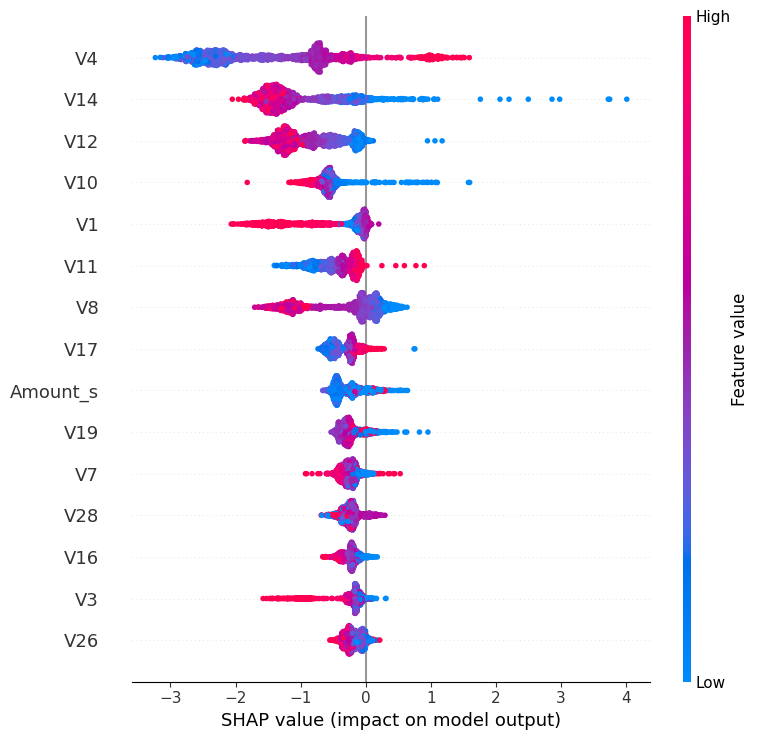

Top 10 features by mean |SHAP|:
V4          1.5208
V14         1.1143
V12         0.8462
V10         0.6134
V1          0.5721
V11         0.4473
V8          0.4456
V17         0.3458
Amount_s    0.3093
V19         0.2696
dtype: float32


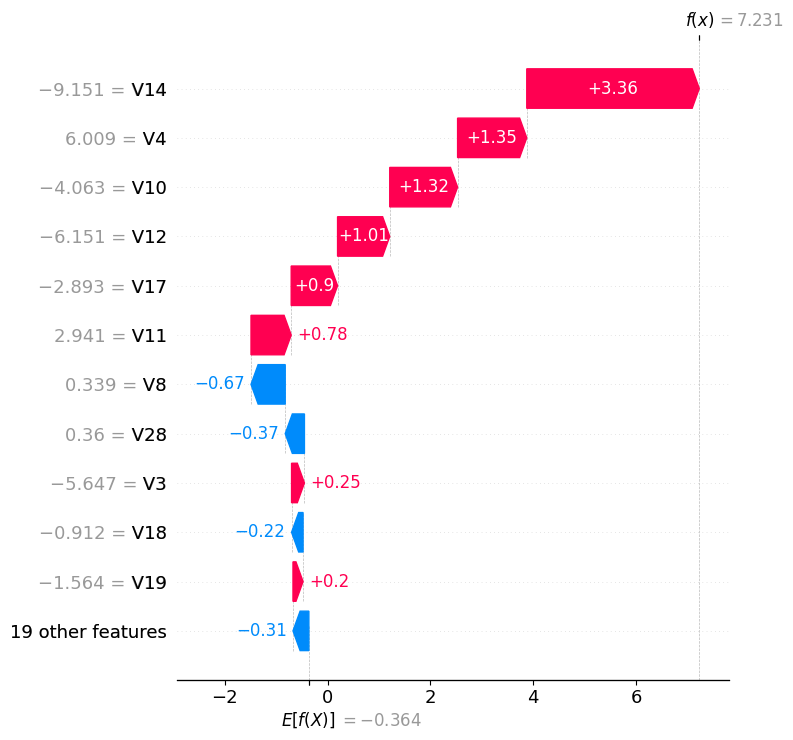

In [ ]:

sample = Xte[best_feats].sample(2000, random_state=SEED)
contribs = final_model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)
shap_vals, base_val = contribs[:, :-1], contribs[0, -1]
shap.summary_plot(shap_vals, sample, max_display=15, show=False)
savefig('figure_9_shap_summary')

mean_abs = pd.Series(np.abs(shap_vals).mean(0), index=best_feats).sort_values(ascending=False)
print('Top 10 features by mean |SHAP|:'); print(mean_abs.head(10).round(4))
savetab(mean_abs.rename('mean_abs_shap').to_frame(), 'table_13_shap_importance', index=True)

hit = np.where((pred == 1) & (y_te.values == 1))[0]
if len(hit):
    row = Xte[best_feats].iloc[[hit[0]]]
    c = final_model.get_booster().predict(xgb.DMatrix(row), pred_contribs=True)[0]
    shap.plots.waterfall(shap.Explanation(values=c[:-1], base_values=c[-1], data=row.values[0],
                                          feature_names=best_feats), max_display=12, show=False)
    savefig('figure_10_shap_single_fraud')

In [ ]:
one = Xte[best_feats].iloc[[0]]; final_model.predict_proba(one)
t0 = time.perf_counter()
for _ in range(500): final_model.predict_proba(one)
lat_ms = (time.perf_counter() - t0) / 500 * 1000
t0 = time.perf_counter(); final_model.predict_proba(Xte[best_feats]); tps = len(Xte) / (time.perf_counter() - t0)
print(f'Single-transaction latency: {lat_ms:.2f} ms (paper: 12 ms) | batch throughput: {tps:,.0f} transactions/s')

Single-transaction latency: 7.75 ms (paper: 12 ms) | batch throughput: 39,125 transactions/s


In [ ]:
best_row = final[final.Model == f'Tuned @{PRIMARY_RULE}(OOF)'].iloc[0]
a_row = final[final.Model.str.startswith('A.')].iloc[0]
summary = pd.DataFrame({
    'Paper (reported)': [0.95, 0.89, 0.92, 0.98, np.nan, 12.0],
    'Paper replication (A)': [a_row.Precision, a_row.Recall, a_row.F1, a_row.AUC_ROC, a_row.PR_AUC, np.nan],
    'Tuned XGBoost (ours)': [best_row.Precision, best_row.Recall, best_row.F1, best_row.AUC_ROC, best_row.PR_AUC, lat_ms],
}, index=['Precision', 'Recall', 'F1', 'AUC-ROC', 'PR-AUC', 'Latency (ms)'])
display(summary.round(4)); savetab(summary, 'table_14_summary_vs_paper', index=True)

final_model.save_model(f'{SAVE_DIR}/xgb_tuned_model.json')        # deployable model file
joblib.dump({'amount_scaler': scaler, 'hour_scaler': hour_scaler, 'features': best_feats,
             'threshold': t_best, 'threshold_rule': PRIMARY_RULE, 'all_thresholds': tuned_rules,
             'params': best_params}, f'{SAVE_DIR}/xgb_tuned_preprocessing.joblib')
with open(f'{SAVE_DIR}/best_hyperparameters.json', 'w') as f:
    json.dump({'cv_pr_auc': study.best_value, **study.best_params}, f, indent=2)
print('Saved model, preprocessing and hyperparameters to', SAVE_DIR)

,Paper (reported),Paper replication (A),Tuned XGBoost (ours)
Precision,0.95,0.4583,0.8485
Recall,0.89,0.7432,0.7568
F1,0.92,0.5670,0.8000
AUC-ROC,0.98,0.9282,0.9879
PR-AUC,NaN,0.3475,0.8052
Latency (ms),12.00,NaN,7.7499


Saved model, preprocessing and hyperparameters to /content/drive/MyDrive/CloudAI_CW1
